# B1 — Understand and count the sign sequences

**P2 task:** ranked sign frequencies (Zipf plot), sequence lengths, and signs
appearing exactly once. This notebook includes the theory, runnable code,
checks and two figures for the report. Run the cells from top to bottom.

Select this project's `.venv/bin/python` as the VS Code notebook kernel.
No training, image recognition or bounding boxes are involved in B1.

Your original notes and image are preserved below. A clarification follows
them because “token” and “distinct sign type” need different meanings.

# 1. Data and Terminology


    The hierarchy of the data roughly is:
    1. Corpus = Multiple seals/sequences. 
    2. Seal = Physical Stone Object
    3. which contains a inscription 
    4. Inscription = Sequence of signs in a particular order, according to that seal
    5. each sign type has a ID 
    6. Sequence = List of IDs in reading order, out data loader will load the sequence directly in reading order so no need to reverse it again. 
    7. Token = ID, its position. So a sequence has as many token as its length but may have lesser signs since signs could repeat. Hence we use token to uniquely identify a sign in a sequence. 

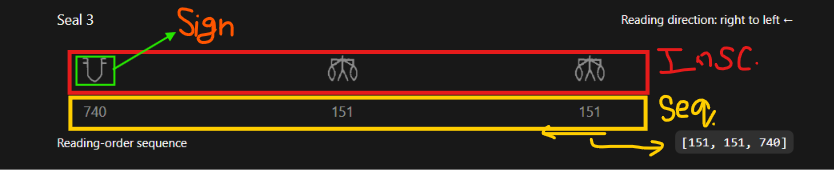

## The corpus becomes for us - 
```python 
corpus = [
    [151, 105, 151, 740],
    [151, 740],
    [151, 151, 740],
]
```

## 1. Clarify the terminology

- **Sign type:** a particular category of symbol, identified here by a Wells ID.
- **Token:** one occurrence of a sign type at one position. It is not a new ID.
- **Sequence:** an ordered list of sign IDs for one inscription in this dataset.
- **Corpus:** the collection of sequences we analyse.

`[151, 151, 740]` has **3 tokens**, **2 distinct types**, and **length 3**.
Its first and second tokens have the same sign ID. You can refer to a token by
its sequence and position, but the Python data only stores the IDs in order.

The dataset is not a list of photographed objects: it contains 1,837 unique,
filtered inscriptions, without object metadata. Repeated identical texts were
removed upstream. Counts therefore describe this particular corpus, not all
known Indus objects. See `data/README.md` for exclusions and provenance.

These sequences use **Wells IDs**. Our offline IM77 reader uses **Mahadevan IDs**.
Identical integers across those systems need not denote the same sign.
We do not combine them in B1.

## 2. Learn the counting on a tiny example

This is an invented teaching corpus, not three historical inscriptions:

```text
Sequence 1: 151 105 151 740  (4 tokens)
Sequence 2: 151 740          (2 tokens)
Sequence 3: 151 151 740      (3 tokens)
```

Hand count: sign 151 occurs 5 times, sign 740 occurs 3 times, and sign 105
occurs once. Total = 9 tokens, 3 types, 1 singleton type. Sequence lengths
are 4, 2, 3; their mean is `(4 + 2 + 3) / 3 = 3`.

A **singleton** (also called a hapax) is a sign type occurring exactly once
in the entire corpus. A sign repeated once in every sequence is not a singleton.

In [1]:
from pathlib import Path
import sys
import json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from indus.data import load_sequences, REPO_ROOT, SEQUENCES_FILE
from indus.descriptive import count_signs, count_lengths, summarize_corpus

print("Python interpreter:", sys.executable)
print("Project:", REPO_ROOT)
toy = [[151, 105, 151, 740], [151, 740], [151, 151, 740]]
assert count_signs(toy) == {151: 5, 740: 3, 105: 1}
assert count_lengths(toy) == {2: 1, 3: 1, 4: 1}
toy_summary = summarize_corpus(toy)
assert toy_summary["n_tokens"] == 9
assert toy_summary["n_types"] == 3
assert toy_summary["n_singletons"] == 1
assert toy_summary["mean_length"] == 3
assert toy_summary["median_length"] == 3
assert toy_summary["singleton_type_fraction"] == 1 / 3
assert toy_summary["singleton_token_fraction"] == 1 / 9
assert summarize_corpus([[151, 151]])["n_singletons"] == 0
for invalid in ([], [[]], [[151], []]):
    try:
        summarize_corpus(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Empty input should fail clearly")
print("Hand-counted example and empty-input checks passed.")
display(pd.Series(toy_summary, name="toy corpus"))

Python interpreter: /home/devambhavsar/ML/AI_Project/.venv/bin/python
Project: /home/devambhavsar/ML/AI_Project
Hand-counted example and empty-input checks passed.


n_sequences                 3.000000
n_tokens                    9.000000
n_types                     3.000000
n_singletons                1.000000
singleton_type_fraction     0.333333
singleton_token_fraction    0.111111
min_length                  2.000000
max_length                  4.000000
mean_length                 3.000000
median_length               3.000000
Name: toy corpus, dtype: float64

### What the Python is doing

`import` brings existing tools into the notebook. `toy` is a list of lists:
each inner list is one sequence. A `for` loop visits each sequence and then
each sign within it. `Counter` is a dictionary-like counting table; an unseen
ID starts at zero. `counts[sign] += 1` adds one occurrence.

`len(sequence)` counts positions, including repeats. `sum(lengths)` adds the
lengths. `signs.values()` gives occurrence counts, without the IDs.
`sum(count == 1 for count in signs.values())` counts the true comparisons:
Python treats `True` as 1 and `False` as 0 here.

A function defined with `def` packages these steps for reuse. `return` gives
its answer back to the caller. `assert` checks a claim and stops execution if
it is false. We wrote the expected toy answers by hand, independently of the
functions. Read `src/indus/descriptive.py` alongside this explanation.

## 3. Load the real corpus and verify its totals

`load_sequences()` reads and parses the source through the team's shared
loader. It already returns the project's **reading order**; do not reverse
it again. We do not parse or edit the raw CSV ourselves.

B1's counts and lengths do not depend on direction. Reversing a sequence
changes positions but neither the signs present nor how many there are.
This will cease to be true for B2 start/end counts and B3 transitions.

In [2]:
sequences = load_sequences()
summary = summarize_corpus(sequences)
signs = count_signs(sequences)
lengths = count_lengths(sequences)

expected = {"n_sequences": 1837, "n_tokens": 8359, "n_types": 568,
            "n_singletons": 219, "min_length": 2, "max_length": 13}
for key, known_value in expected.items():
    assert summary[key] == known_value, (key, summary[key], known_value)

# A separate plain-dictionary calculation checks every sign count.
manual_counts = {}
for sequence in sequences:
    for sign in sequence:
        manual_counts[sign] = manual_counts.get(sign, 0) + 1
assert dict(signs) == manual_counts
assert sum(signs.values()) == summary["n_tokens"]
assert sum(lengths.values()) == summary["n_sequences"]
assert sum(length * count for length, count in lengths.items()) == summary["n_tokens"]
reversed_sequences = [sequence[::-1] for sequence in sequences]
assert summarize_corpus(reversed_sequences) == summary
assert count_signs(reversed_sequences) == signs
assert count_lengths(reversed_sequences) == lengths

print("Corpus reference totals, independent counts and consistency checks passed.")
print("First three real sequences:", sequences[:3])
display(pd.Series(summary, name="ICIT corpus"))

Corpus reference totals, independent counts and consistency checks passed.
First three real sequences: [[142, 1], [33, 812, 125, 354, 304, 1], [351, 368, 1]]


n_sequences                 1837.000000
n_tokens                    8359.000000
n_types                      568.000000
n_singletons                 219.000000
singleton_type_fraction        0.385563
singleton_token_fraction       0.026199
min_length                     2.000000
max_length                    13.000000
mean_length                    4.550354
median_length                  4.000000
Name: ICIT corpus, dtype: float64

## 4. Rank signs by frequency

For sign type `s`, its **count** `c(s)` is the number of its tokens in the corpus.
Its **relative frequency** is `c(s) / N`, where `N = 8,359` tokens.
This estimates the chance of seeing that sign when selecting one corpus token
uniformly at random. It is not a prediction conditioned on neighbouring signs.

Rank 1 is the most frequent sign; rank 2 is the next most frequent, and so on.
**Rank is not a sign ID.** We break count ties using the smaller Wells ID first
so the table always has the same order. Tied signs are equally frequent.

A pandas `DataFrame` is a table with named columns. `sorted` orders the ID/count
pairs; the key `(-count, sign_id)` means descending counts then ascending IDs.

In [3]:
ranked = sorted(signs.items(), key=lambda item: (-item[1], item[0]))
frequency_table = pd.DataFrame(ranked, columns=["wells_id", "count"])
frequency_table.insert(0, "rank", range(1, len(ranked) + 1))
frequency_table["relative_frequency"] = frequency_table["count"] / summary["n_tokens"]
singleton_ids = sorted(sign for sign, count in signs.items() if count == 1)

assert frequency_table["count"].is_monotonic_decreasing
assert abs(frequency_table["relative_frequency"].sum() - 1) < 1e-12
assert len(singleton_ids) == 219
display(frequency_table.head(15))
print(f"Singleton types: {len(singleton_ids)} / {summary['n_types']} = "
      f"{summary['singleton_type_fraction']:.2%}")
print(f"Singleton tokens: {len(singleton_ids)} / {summary['n_tokens']} = "
      f"{summary['singleton_token_fraction']:.2%}")

,rank,wells_id,count,relative_frequency
0,1,740,902,0.107908
1,2,2,463,0.055389
2,3,32,217,0.025960
3,4,220,209,0.025003
4,5,400,209,0.025003
5,6,240,180,0.021534
6,7,390,154,0.018423
7,8,520,154,0.018423
8,9,33,149,0.017825
9,10,60,147,0.017586


Singleton types: 219 / 568 = 38.56%
Singleton tokens: 219 / 8359 = 2.62%


## 5. Figure 1 — rank versus frequency (Zipf plot)

The horizontal axis is frequency rank. The vertical axis is occurrence count.
Both use logarithmic scales: equal spacing represents equal multiplication,
such as 1 → 10 → 100, rather than equal addition. This lets us see frequent
signs and the long tail of rare signs together.

An ideal Zipf relationship is `c(r) ≈ K / r^a`. Taking logarithms gives
`log c(r) ≈ log K - a log r`, a straight line with slope `-a`.
We call this a Zipf plot because of its axes; we do **not** fit or establish
a power law, infer sign meanings, or prove that the script encodes language.

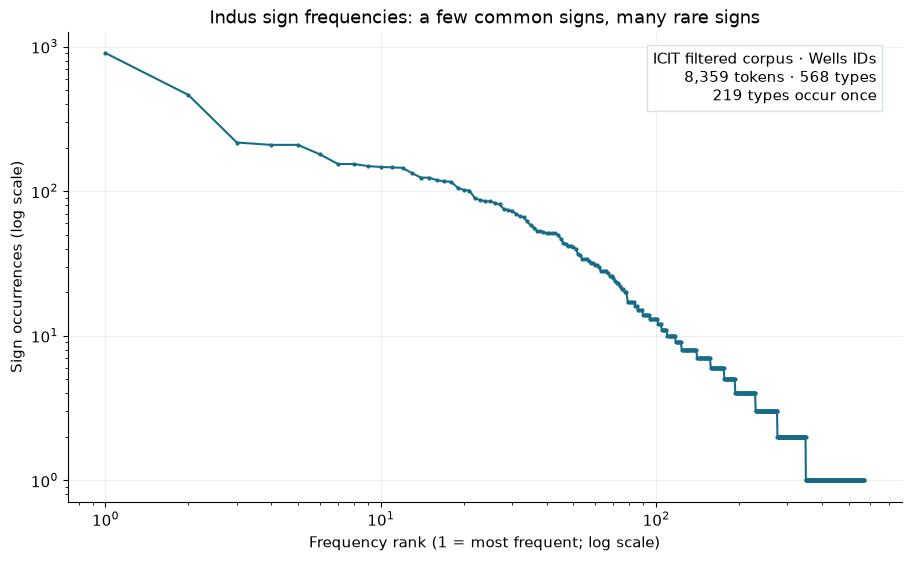

In [4]:
figures = REPO_ROOT / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
ax.loglog(frequency_table["rank"], frequency_table["count"],
          color="#176B87", linewidth=1.5, marker=".", markersize=4)
ax.set(title="Indus sign frequencies: a few common signs, many rare signs",
       xlabel="Frequency rank (1 = most frequent; log scale)",
       ylabel="Sign occurrences (log scale)")
ax.grid(True, which="major", alpha=0.2)
ax.text(0.97, 0.96, "ICIT filtered corpus · Wells IDs\n8,359 tokens · 568 types\n219 types occur once",
        transform=ax.transAxes, ha="right", va="top",
        bbox={"facecolor": "white", "edgecolor": "#D5DFE5", "alpha": 0.95})
fig.savefig(figures / "b1_zipf.png", dpi=180)
plt.show()
plt.close(fig)

## 6. Figure 2 — sequence-length distribution

The horizontal axis is the number of tokens in one sequence. The vertical
axis counts how many sequences have that length. Unlike the Zipf plot,
these are ordinary linear axes. We include zero-height bars for any missing
integer lengths between the minimum and maximum.

**Mean length** = total tokens / number of sequences = `8,359 / 1,837`.
**Median length** = the middle value after sorting all 1,837 lengths.
**Mode length** = the length occurring in the greatest number of sequences.
Short texts are a property of this filtered corpus; the source excludes
single-sign, multiline and damaged texts.

,length,n_sequences,relative_frequency
0,2,265,0.144257
1,3,361,0.196516
2,4,352,0.191617
3,5,350,0.190528
4,6,232,0.126293
5,7,149,0.081111
6,8,56,0.030484
7,9,39,0.021230
8,10,19,0.010343
9,11,7,0.003811


Mean length: 4.5504; median: 4; modes: [3]


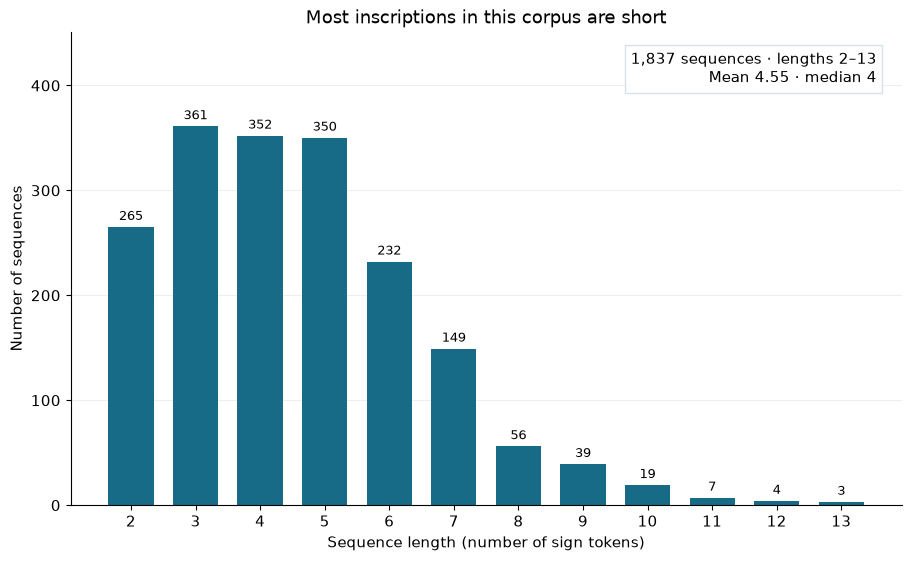

In [5]:
length_table = pd.DataFrame({
    "length": range(summary["min_length"], summary["max_length"] + 1)
})
length_table["n_sequences"] = [lengths[length] for length in length_table["length"]]
length_table["relative_frequency"] = length_table["n_sequences"] / summary["n_sequences"]
max_count = max(lengths.values())
modes = sorted(length for length, count in lengths.items() if count == max_count)
display(length_table)
print(f"Mean length: {summary['mean_length']:.4f}; median: {summary['median_length']}; modes: {modes}")

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
bars = ax.bar(length_table["length"], length_table["n_sequences"], color="#176B87", width=0.7)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(title="Most inscriptions in this corpus are short",
       xlabel="Sequence length (number of sign tokens)", ylabel="Number of sequences")
ax.set_xticks(length_table["length"])
ax.set_ylim(0, max_count * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.text(0.97, 0.96,
        f"1,837 sequences · lengths 2–13\nMean {summary['mean_length']:.2f} · median {summary['median_length']:g}",
        transform=ax.transAxes, ha="right", va="top",
        bbox={"facecolor": "white", "edgecolor": "#D5DFE5", "alpha": 0.95})
fig.savefig(figures / "b1_lengths.png", dpi=180)
plt.show()
plt.close(fig)

## 7. Save the tables and record exactly what they describe

Figures are committed report assets. Regenerable tables go in
`data/processed/b1/`, which Git ignores. The summary records the dataset,
numbering, order and SHA-256 source checksum, so a later reader can tell
which source file these results describe. A checksum identifies bytes;
it does not certify archaeological correctness.

Nothing here modifies `data/raw/`. No random sampling or model training is
involved, so a random seed and train/test split are unnecessary for B1.

In [6]:
import hashlib

processed = REPO_ROOT / "data/processed/b1"
processed.mkdir(parents=True, exist_ok=True)
frequency_table.to_csv(processed / "sign_frequencies.csv", index=False)
length_table.to_csv(processed / "sequence_lengths.csv", index=False)
pd.DataFrame({"wells_id": singleton_ids}).to_csv(processed / "singleton_signs.csv", index=False)
source_hash = hashlib.sha256(SEQUENCES_FILE.read_bytes()).hexdigest()
saved_summary = {"dataset": "ICIT 1837 filtered unique inscriptions",
                 "numbering": "Wells", "order": "reading",
                 "source": str(SEQUENCES_FILE.relative_to(REPO_ROOT)),
                 "source_sha256": source_hash, **summary, "mode_lengths": modes}
(processed / "summary.json").write_text(json.dumps(saved_summary, indent=2) + "\n")
assert pd.read_csv(processed / "sign_frequencies.csv")["count"].sum() == 8359
assert pd.read_csv(processed / "sequence_lengths.csv")["n_sequences"].sum() == 1837
print("Saved figures:", figures / "b1_zipf.png", "and", figures / "b1_lengths.png")
print("Saved tables and summary:", processed)

Saved figures: /home/devambhavsar/ML/AI_Project/reports/figures/b1_zipf.png and /home/devambhavsar/ML/AI_Project/reports/figures/b1_lengths.png
Saved tables and summary: /home/devambhavsar/ML/AI_Project/data/processed/b1


## 8. What we can say, and what the checks establish

B1 describes 1,837 sequences containing 8,359 tokens and 568 distinct Wells
types. Of those types, 219 appear once. That is **38.56% of types**, but only
**2.62% of tokens**: different denominators answer different questions.

Rare signs have little evidence available for estimating their behaviour.
This motivates careful smoothing later in B5; we have not implemented it here.
B1 ignores position and neighbours. B2 asks where signs occur, and B3 asks
which signs follow one another.

**Checks:** a manually counted toy corpus, repeated-sign and invalid-input
cases, the task's six reference totals, an independent dictionary count,
two conservation identities for length counts, direction invariance,
rank/probability checks, and saved-table readback. The existing repository
test suite is also run outside the notebook.

These catch counting and integration mistakes. They do not independently
establish the source transcriptions, sign taxonomy, corpus completeness,
a linguistic interpretation or an actual Zipf law.

**Try explaining it yourself:** Why is 219/568 different from 219/8359?
Why is rank 1 not necessarily sign ID 1? Why doesn't reversing the sequences
change B1? Can you manually count the toy corpus and predict every output?

**Local references:** `docs/TASKS.md` (B1 requirements), `data/README.md`
(source and limitations), `src/indus/data.py` (loader),
`src/indus/descriptive.py` (the new counting functions).